In [1]:
import pandas as pd 

In [2]:
apps: pd.DataFrame = pd.read_csv('../dataset/application_record.csv')
records: pd.DataFrame = pd.read_csv('../dataset/credit_record.csv')

In [3]:
apps.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [4]:
records.head()

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [5]:
apps.shape, records.shape

((438557, 18), (1048575, 3))

In [6]:
apps['ID'].duplicated().sum()

np.int64(47)

In [7]:
records['ID'].duplicated().sum()

np.int64(1002590)

In [8]:
records[records['ID'].duplicated()].iloc[:10]

,ID,MONTHS_BALANCE,STATUS
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
5,5001712,-1,C
6,5001712,-2,C
7,5001712,-3,C
8,5001712,-4,C
9,5001712,-5,C
10,5001712,-6,C
11,5001712,-7,C


there are multiple records for each id 
- the credit risk of a person is the summed month status that they have had 
- calculate the summed score for each id 


In [9]:
# first check the overlap 
# rows in apps which are not in records 
len(apps[~apps['ID'].isin(records['ID'])]['ID'].unique())

402053

In [10]:
# rows in records which are not in apps 
len(records[~records['ID'].isin(apps['ID'])]['ID'].unique())

9528

the eval set is made from these ID values which are not in the records??? 
# TODO ... 

In [11]:
risk: pd.DataFrame = records.copy(deep = True)
risk.head()

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [12]:
r = risk.groupby(['ID'])

for i, (name, group ) in enumerate(r): 
    if i == 3: break 
    print(name)
    print(group)

(5001711,)
        ID  MONTHS_BALANCE STATUS
0  5001711               0      X
1  5001711              -1      0
2  5001711              -2      0
3  5001711              -3      0
(5001712,)
         ID  MONTHS_BALANCE STATUS
4   5001712               0      C
5   5001712              -1      C
6   5001712              -2      C
7   5001712              -3      C
8   5001712              -4      C
9   5001712              -5      C
10  5001712              -6      C
11  5001712              -7      C
12  5001712              -8      C
13  5001712              -9      0
14  5001712             -10      0
15  5001712             -11      0
16  5001712             -12      0
17  5001712             -13      0
18  5001712             -14      0
19  5001712             -15      0
20  5001712             -16      0
21  5001712             -17      0
22  5001712             -18      0
(5001713,)
         ID  MONTHS_BALANCE STATUS
23  5001713               0      X
24  5001713              -1

the mapping for the values is: 
x =0 
c = 1 
1 = 2 
2 = 3 
3= 4 
4  = 5 
5= 6 

In [13]:
r = risk.groupby('ID', as_index= False) 
# keep index seperate from ID col

for i , (name, group) in enumerate(r): 
    if i==2: break 

    print(name)
    print(group)

5001711
        ID  MONTHS_BALANCE STATUS
0  5001711               0      X
1  5001711              -1      0
2  5001711              -2      0
3  5001711              -3      0
5001712
         ID  MONTHS_BALANCE STATUS
4   5001712               0      C
5   5001712              -1      C
6   5001712              -2      C
7   5001712              -3      C
8   5001712              -4      C
9   5001712              -5      C
10  5001712              -6      C
11  5001712              -7      C
12  5001712              -8      C
13  5001712              -9      0
14  5001712             -10      0
15  5001712             -11      0
16  5001712             -12      0
17  5001712             -13      0
18  5001712             -14      0
19  5001712             -15      0
20  5001712             -16      0
21  5001712             -17      0
22  5001712             -18      0


In [14]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories = [['X', 'C', '0', '1', '2', '3', '4', '5']])
risk[['ENCODED_STATUS']] = encoder.fit_transform(risk[['STATUS']])

In [15]:
risk.head()

,ID,MONTHS_BALANCE,STATUS,ENCODED_STATUS
0,5001711,0,X,0.0
1,5001711,-1,0,2.0
2,5001711,-2,0,2.0
3,5001711,-3,0,2.0
4,5001712,0,C,1.0


In [16]:
risk_grouped = risk.groupby('ID', as_index= False)

In [17]:
for i, (name, group ) in enumerate(risk_grouped): 
    if i == 3: break 

    print(name)
    print(group)

5001711
        ID  MONTHS_BALANCE STATUS  ENCODED_STATUS
0  5001711               0      X             0.0
1  5001711              -1      0             2.0
2  5001711              -2      0             2.0
3  5001711              -3      0             2.0
5001712
         ID  MONTHS_BALANCE STATUS  ENCODED_STATUS
4   5001712               0      C             1.0
5   5001712              -1      C             1.0
6   5001712              -2      C             1.0
7   5001712              -3      C             1.0
8   5001712              -4      C             1.0
9   5001712              -5      C             1.0
10  5001712              -6      C             1.0
11  5001712              -7      C             1.0
12  5001712              -8      C             1.0
13  5001712              -9      0             2.0
14  5001712             -10      0             2.0
15  5001712             -11      0             2.0
16  5001712             -12      0             2.0
17  5001712         

In [18]:
risk_grouped = risk.groupby('ID', as_index= False)['ENCODED_STATUS'].sum()

In [19]:
risk_grouped.head()

,ID,ENCODED_STATUS
0,5001711,6.0
1,5001712,29.0
2,5001713,0.0
3,5001714,0.0
4,5001715,0.0


In [20]:
risk_grouped['ID'].duplicated().sum()

np.int64(0)

the encoded status gives the summed risk 

this is a classification problem though, so the risk has to be split into classes 

to first see what is the best way to approach this, do a histogram 

In [21]:
import seaborn as sns 

<Axes: xlabel='ENCODED_STATUS', ylabel='Count'>

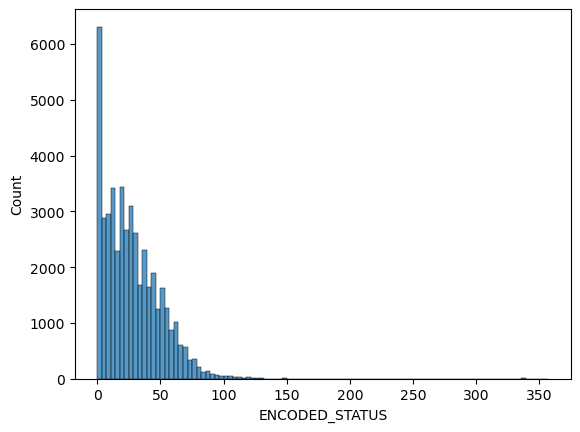

In [22]:
sns.histplot(risk_grouped['ENCODED_STATUS'], bins = 100)

the best way to discreditize is to use the KBinsDiscretizer. this allows for xtrain to be fit, and testx to be transformed which reduces data leakage 

In [23]:
from sklearn.preprocessing import KBinsDiscretizer

In [24]:
quantile_bin_transformer = KBinsDiscretizer(n_bins = 3, encode = 'ordinal', strategy= 'quantile') 
# quantile means equal frequency of each class, which is good for this case 
    # not uniform width or clustered 
uniform_bin_transformer = KBinsDiscretizer(n_bins = 3, encode = 'ordinal', strategy= 'uniform') 


see which strategy is best: equal output frequency or equal bin width
not enough features to look at clusering 

In [25]:
risk_grouped[['QUANTILE_STATUS']] = quantile_bin_transformer.fit_transform(risk_grouped[['ENCODED_STATUS']])
risk_grouped[['UNIFORM_STATUS']] = uniform_bin_transformer.fit_transform(risk_grouped[['ENCODED_STATUS']])

risk_grouped.head()

/Users/malinimanimaran/opt/miniconda3/envs/customer_risk_project/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


,ID,ENCODED_STATUS,QUANTILE_STATUS,UNIFORM_STATUS
0,5001711,6.0,0.0,0.0
1,5001712,29.0,1.0,0.0
2,5001713,0.0,0.0,0.0
3,5001714,0.0,0.0,0.0
4,5001715,0.0,0.0,0.0


In [26]:
risk_grouped['QUANTILE_STATUS'].value_counts(())

QUANTILE_STATUS
1.0    15866
2.0    15845
0.0    14274
Name: count, dtype: int64

In [27]:
risk_grouped['UNIFORM_STATUS'].value_counts()

UNIFORM_STATUS
0.0    45899
1.0       72
2.0       14
Name: count, dtype: int64

it makes most sense to use quantile binning to begin with, so that there is even distribution 

this means that there wont be issues such as weighting cel loss 

credit record pipeline (target pipeline is below)

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import FunctionTransformer, Pipeline

In [41]:
records =pd.read_csv('../dataset/credit_record.csv')

# encode the status 
encode= ColumnTransformer(transformers=[
    ('encoded', OrdinalEncoder(categories= [['X', 'C', '0', '1', '2', '3', '4', '5']]) ,[ 'STATUS'])
    ], 
    remainder='passthrough', 
    verbose_feature_names_out=False).set_output(transform='pandas')

# sum over the status to calcualte the risk 
def get_risk(data: pd.DataFrame ) -> pd.DataFrame: 
    # always get copy 
    data  = data.copy(deep = True)

    # group by and get the summs over encoded status 
    scored_data = data.groupby('ID',as_index= False )['STATUS'].sum() # NOTE that this drops the months balance feature as wanted 
    return scored_data

function_transformer_get_risk= FunctionTransformer(get_risk) # not ()

discretize = ColumnTransformer(
    transformers=[
        ('keep id', 'passthrough', ['ID']),
        ('risk', KBinsDiscretizer(n_bins = 3, encode = 'ordinal', strategy= 'quantile'), ['STATUS'])
    ], 
    remainder= 'drop', 
    verbose_feature_names_out=False
).set_output(transform= 'pandas')


pipeline = Pipeline(steps=[
    ('encode', encode), 
    ('sum_risk', function_transformer_get_risk), 
    ('bin', discretize)
]) 

final_records= pipeline.fit_transform(records)
# records.head()
final_records.head()

/Users/malinimanimaran/opt/miniconda3/envs/customer_risk_project/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


,ID,STATUS
0,5001711,0.0
1,5001712,1.0
2,5001713,0.0
3,5001714,0.0
4,5001715,0.0


In [42]:
final_records.STATUS.value_counts()

STATUS
1.0    15866
2.0    15845
0.0    14274
Name: count, dtype: int64